In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Скачиваем датасет напрямую в Colab (CSV-версия того же самого датасета UCI)
!wget -q https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/concrete.csv -O concrete.csv

# Создаем папку для графиков
os.makedirs('figures', exist_ok=True)

In [10]:
# Загрузка данных
df = pd.read_csv('concrete.csv')

# Переименуем столбцы для удобства
columns = [
    'Cement', 'Slag', 'Fly_Ash', 'Water', 'Superplasticizer',
    'Coarse_Aggregate', 'Fine_Aggregate', 'Age', 'Strength'
]
df.columns = columns

print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} столбцов\n")
print("--- Первые 5 строк ---")
display(df.head())

Размерность датасета: 1030 строк, 9 столбцов

--- Первые 5 строк ---


,Cement,Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [11]:
print("--- Информация о типах данных ---")
df.info()

print("\n--- Проверка на пропуски (NaN) ---")
print(df.isnull().sum())

print(f"\nКоличество полных дубликатов: {df.duplicated().sum()}")

--- Информация о типах данных ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Cement            1030 non-null   float64
 1   Slag              1030 non-null   float64
 2   Fly_Ash           1030 non-null   float64
 3   Water             1030 non-null   float64
 4   Superplasticizer  1030 non-null   float64
 5   Coarse_Aggregate  1030 non-null   float64
 6   Fine_Aggregate    1030 non-null   float64
 7   Age               1030 non-null   int64  
 8   Strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

--- Проверка на пропуски (NaN) ---
Cement              0
Slag                0
Fly_Ash             0
Water               0
Superplasticizer    0
Coarse_Aggregate    0
Fine_Aggregate      0
Age                 0
Strength            0
dtype: int64

Количество полных дубликатов: 25


In [12]:
print("--- Описательные статистики ---")
display(df.describe().T)

print("\n--- Количество потенциальных выбросов (по правилу IQR) ---")
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).sum()
print(outliers)

--- Описательные статистики ---


,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
Slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
Fly_Ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
Water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
Superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
Coarse_Aggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
Fine_Aggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
Age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
Strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6



--- Количество потенциальных выбросов (по правилу IQR) ---
Cement               0
Slag                 2
Fly_Ash              0
Water                9
Superplasticizer    10
Coarse_Aggregate     0
Fine_Aggregate       5
Age                 59
Strength             4
dtype: int64


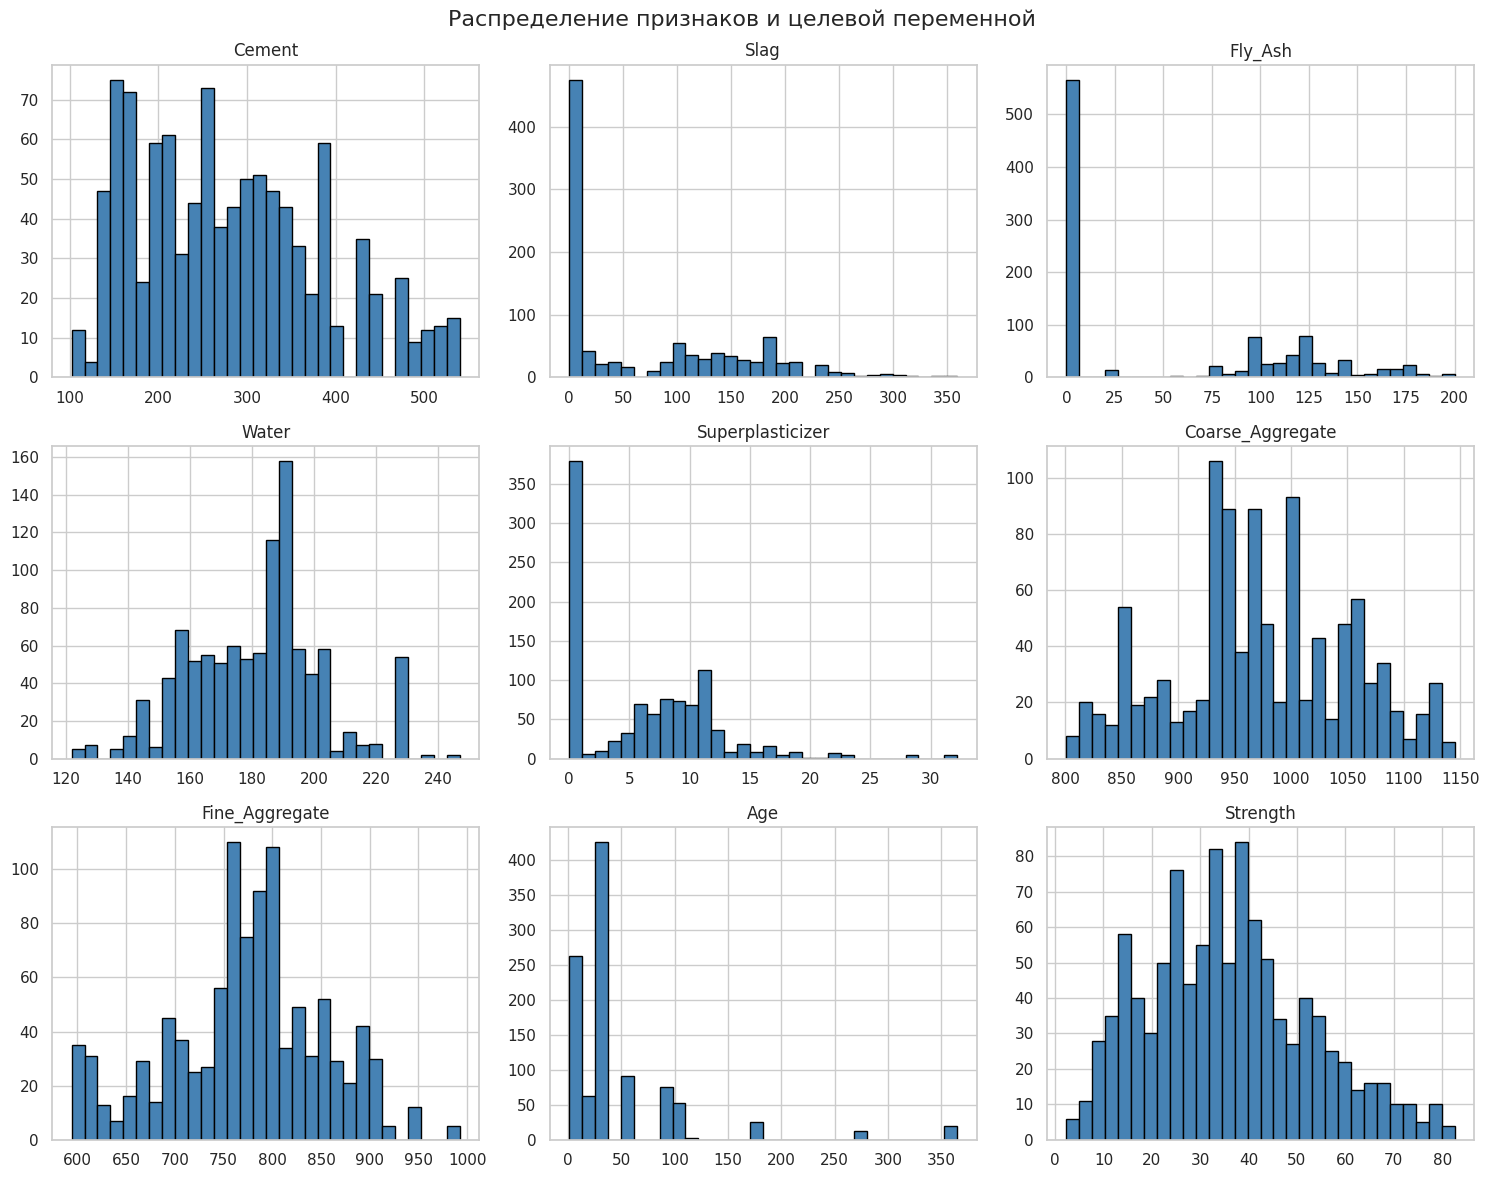

In [13]:
# Гистограммы распределения всех признаков и целевой переменной
df.hist(bins=30, figsize=(15, 12), color='steelblue', edgecolor='black')
plt.suptitle('Распределение признаков и целевой переменной', fontsize=16)
plt.tight_layout()
plt.savefig('figures/01_histograms.png', dpi=300)
plt.show()

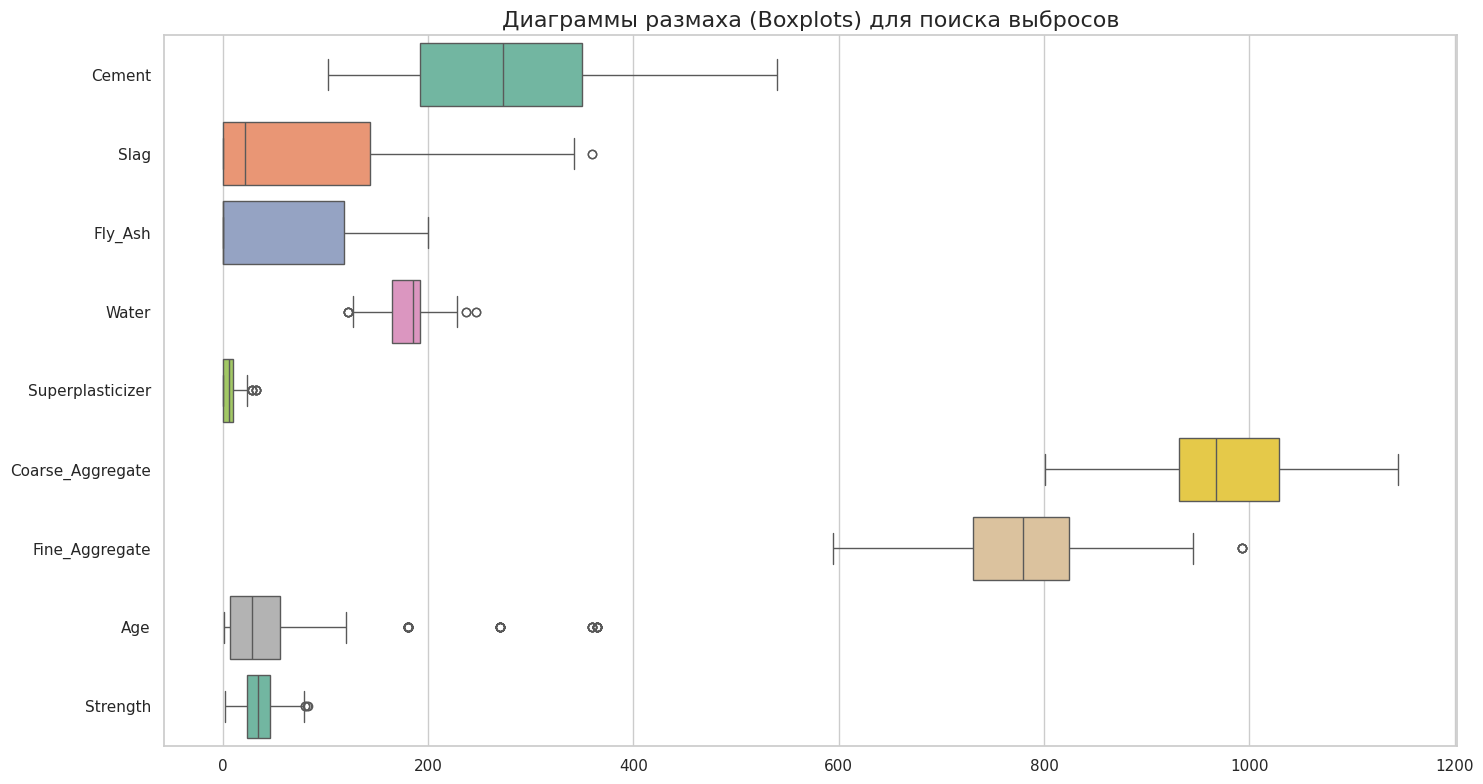

In [14]:
# Boxplot для всех признаков
plt.figure(figsize=(15, 8))
sns.boxplot(data=df, orient="h", palette="Set2")
plt.title('Диаграммы размаха (Boxplots) для поиска выбросов', fontsize=16)
plt.tight_layout()
plt.savefig('figures/02_boxplots.png', dpi=300)
plt.show()

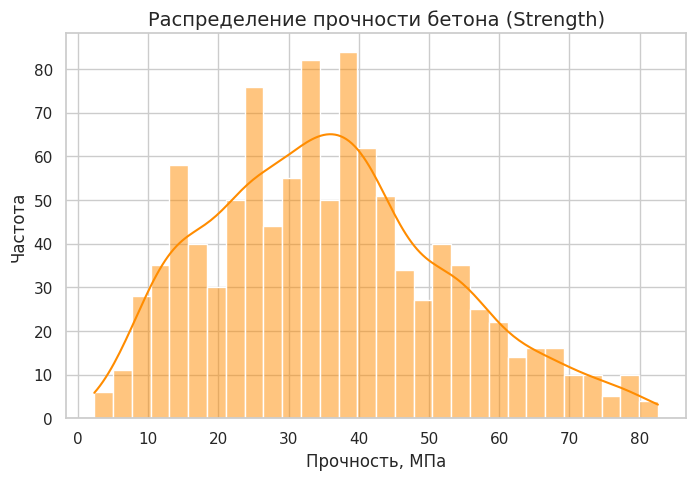

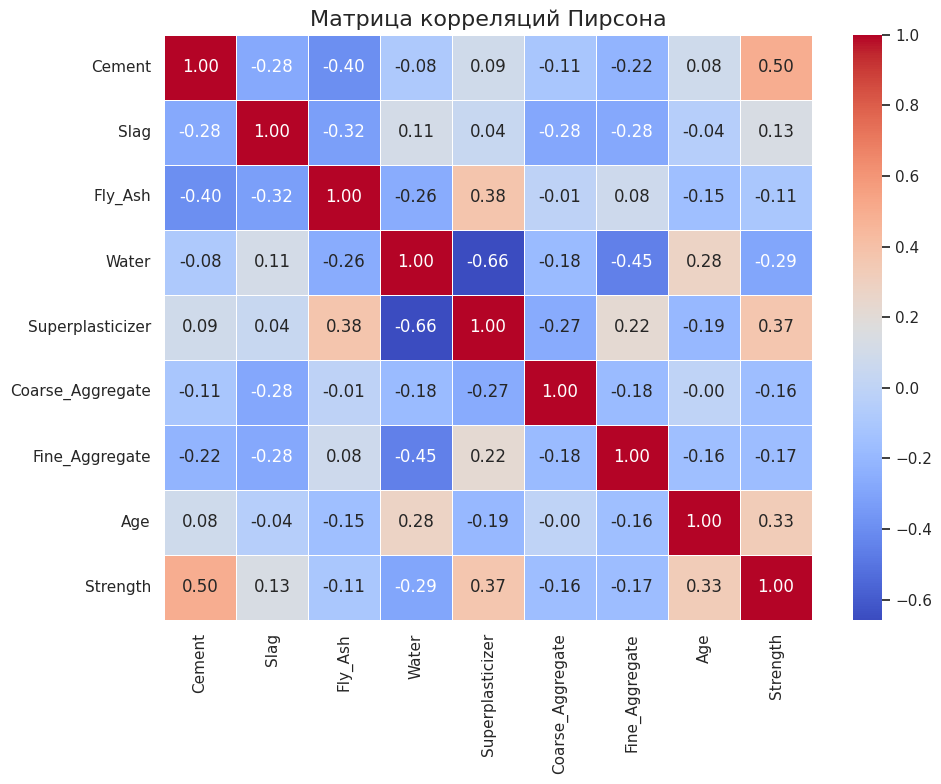

In [15]:
# График для целевой переменной (Strength)
plt.figure(figsize=(8, 5))
sns.histplot(df['Strength'], kde=True, color='darkorange', bins=30)
plt.title('Распределение прочности бетона (Strength)', fontsize=14)
plt.xlabel('Прочность, МПа')
plt.ylabel('Частота')
plt.savefig('figures/03_target_distribution.png', dpi=300)
plt.show()

# Матрица корреляций
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляций Пирсона', fontsize=16)
plt.tight_layout()
plt.savefig('figures/04_correlation_matrix.png', dpi=300)
plt.show()

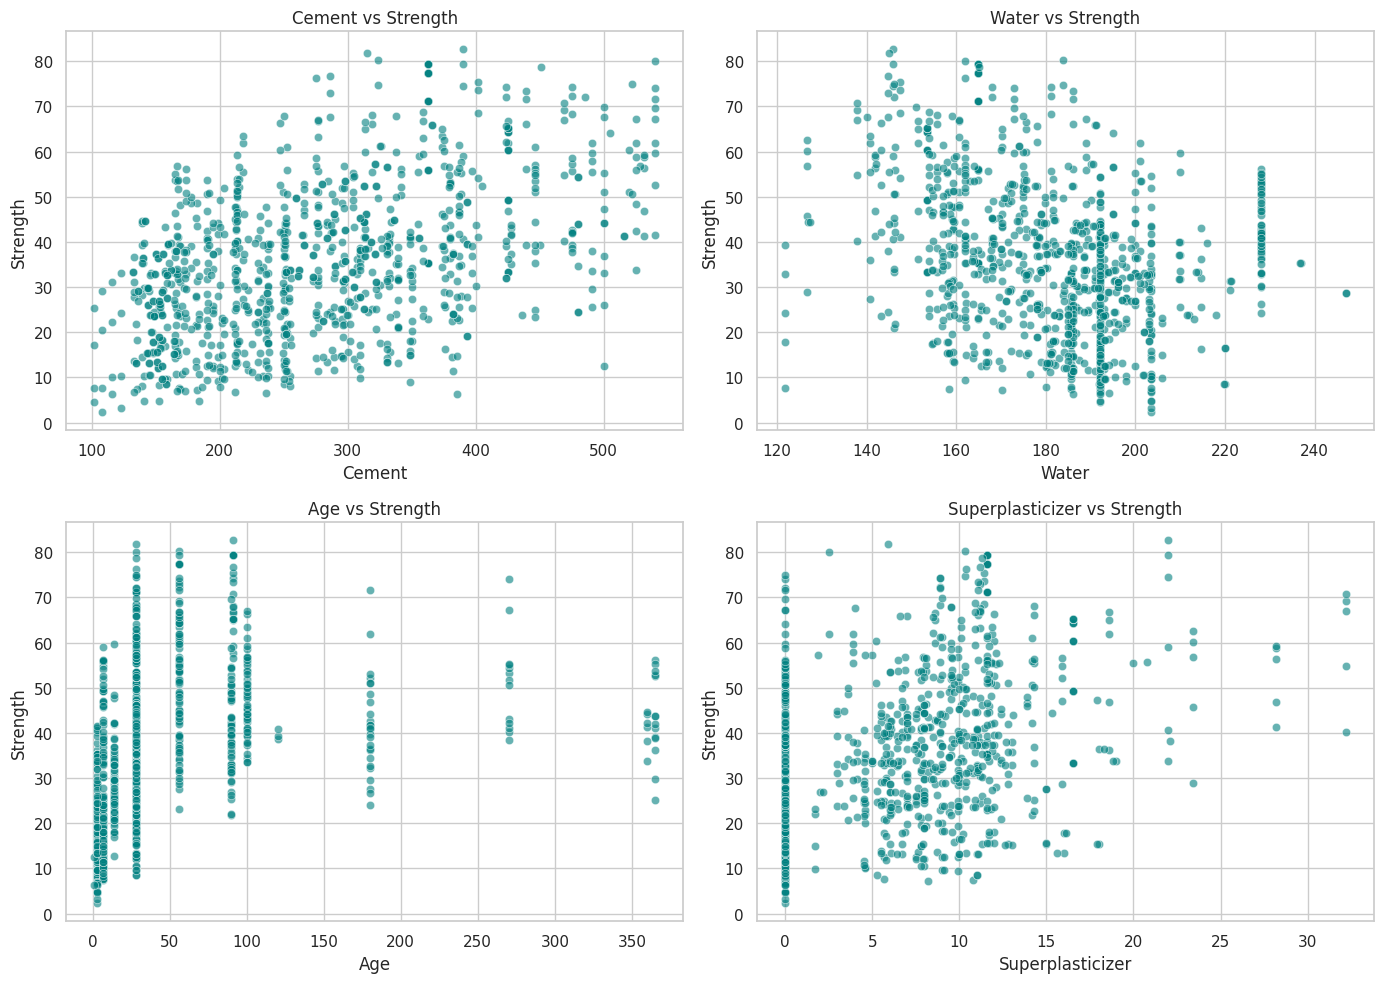

In [16]:
# Scatter plots для наиболее коррелирующих признаков
features = ['Cement', 'Water', 'Age', 'Superplasticizer']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(data=df, x=feature, y='Strength', ax=axes[i], alpha=0.6, color='teal')
    axes[i].set_title(f'{feature} vs Strength')

plt.tight_layout()
plt.savefig('figures/05_scatter_plots.png', dpi=300)
plt.show()

In [17]:
# Упаковываем графики в архив
!zip -r eda_figures.zip figures

# Скачиваем архив с графиками
from google.colab import files
files.download('eda_figures.zip')

# Инструкция для скачивания самого ноутбука:
print("\nЧтобы скачать этот блокнот: Файл -> Скачать -> Скачать .ipynb")

  adding: figures/ (stored 0%)
  adding: figures/03_target_distribution.png (deflated 16%)
  adding: figures/05_scatter_plots.png (deflated 9%)
  adding: figures/02_boxplots.png (deflated 36%)
  adding: figures/04_correlation_matrix.png (deflated 11%)
  adding: figures/01_histograms.png (deflated 29%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Чтобы скачать этот блокнот: Файл -> Скачать -> Скачать .ipynb
